<a href="https://colab.research.google.com/github/MeenakshiRajpurohit/CMPE-297-Natural-Language-Processing/blob/main/asjsu_Week8_20261103.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color: blue"> Week 8 Class Demo</span>

In [ ]:
#!pip install seaborn

In [4]:
import time
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, message=r".*np\.object.*")
from tensorflow.python.ops.numpy_ops import np_config
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, Dense, Input, Dropout, LayerNormalization

np_config.enable_numpy_behavior()

In [5]:
import tensorflow as tf
print(tf.__version__)

2.21.0


## <span style="color: Navy"> Loading the parallel corpora</span>

In [6]:
en_df = pd.read_csv("/content/small_vocab_en.csv", header=None, usecols=[0], nrows=3000)
fr_df = pd.read_csv("/content/small_vocab_fr.csv", header=None, usecols=[0], nrows=3000)

In [7]:
en_df.head()

,0
0,Rhode Island is sometimes quiet during autumn
1,the united states is usually chilly during july
2,california is usually quiet during march
3,the united states is sometimes mild during june
4,your least liked fruit is the grape


In [8]:
fr_df.head()

,0
0,Rhode Island est parfois calme pendant l' auto...
1,les états-unis est généralement froid en juillet
2,california est généralement calme en mars
3,les états-unis est parfois légère en juin
4,votre moins aimé fruit est le raisin


In [9]:
english_sentences =  en_df[0].values
french_sentences = fr_df[0].values

print("English Sentences Numbers: ", len(english_sentences))
print("French Sentences Numbers: ", len(french_sentences))

English Sentences Numbers:  3000
French Sentences Numbers:  3000


In [10]:
def avg_sentence_len(sent):
    return np.mean([len(s.split()) for s in sent])

print("Eng: ", avg_sentence_len(english_sentences))
print("Fre: ", avg_sentence_len(french_sentences))

Eng:  5.955666666666667
Fre:  6.707333333333334


In [11]:
for i in range(len(english_sentences)):
    english_sentences[i] = "sos " + str(english_sentences[i]) + " eos."
    french_sentences[i] = "sos " + str(french_sentences[i]) + " eos."


## Tokenization

In [12]:
num_words = 300
tokenizer_en = Tokenizer(num_words=num_words, filters='!#$%&()*+,-/:;<=>@«»""[\\]^_`{|}~\t\n')
tokenizer_en.fit_on_texts(english_sentences)
english_sentences = tokenizer_en.texts_to_sequences(english_sentences)

word_index = tokenizer_en.word_index
print(f"The number of words in the English vocabulary: {len(word_index)}")

The number of words in the English vocabulary: 201


In [13]:
tokenizer_fr = Tokenizer(num_words=num_words, filters='!#$%&()*+,-/:;<=>@«»""[\\]^_`{|}~\t\n')
tokenizer_fr.fit_on_texts(french_sentences)
french_sentences = tokenizer_fr.texts_to_sequences(french_sentences)

word_index_fr = tokenizer_fr.word_index
print(f"The number of words in the French vocabulary: {len(word_index_fr)}")

The number of words in the French vocabulary: 287


# Padding

In [14]:
english_sentences = pad_sequences(english_sentences, maxlen = 30, padding='post', truncating='post')
french_sentences = pad_sequences(french_sentences, maxlen= 30, padding='post', truncating='post')

# <span style="color: Navy"> Absolute position encoding in the original paper</span>
![1750380246835.png](attachment:cb876078-8ae6-43e8-b739-fde18dea4af9.png)


In Transformer models, unlike recurrent neural networks (RNNs), there is no inherent notion of sequence order because Transformers process tokens in parallel. To provide the model with information about the position of each token in the sequence, positional encodings are added to the input embeddings. These encodings inject sequence order information, enabling the model to capture positional relationships among tokens.

The original Transformer paper ( **"Attention Is All You Need"** by Vaswani et al., 2017) proposes using sine and cosine functions of different frequencies to generate positional encodings.

In [15]:
def get_angles(pos, i, embedding_dim):
    """
    Purpose of get_angles: Calculates the angles used in the sine and cosine functions based on positions and dimensions.
    """
    angle_rates = 1 / np.power(10000, (2 * (i//2)) / np.float32(embedding_dim)) #Integer division to handle even and odd dimensions separately.
    return pos * angle_rates

In [16]:
def positional_encoding(position, embedding_dim):
    """
    Purpose: Generates positional encodings for a given sequence length (position) and embedding dimension (embedding_dim).
    Returns: A tensor of shape (1, position, embedding_dim) containing the positional encodings.
    """
    angle_rads = get_angles(np.arange(position)[:, np.newaxis],
                           np.arange(embedding_dim)[np.newaxis, :], embedding_dim)
    """
    np.arange(position)[:, np.newaxis]: Creates a column vector of shape (position, 1) containing positions from 0 to position-1.
    np.arange(embedding_dim)[np.newaxis, :]: Creates a row vector of shape (1, embedding_dim) containing dimensions from 0 to embedding_dim-1.
    After broadcast, will be (position, embedding_dim)
    """

    # apply sin to even indices in the array. ie 2i
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])

    # apply cos to odd indices in the array. ie 2i+1
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])

    pos_encoding = angle_rads[np.newaxis, ...]  #Adding a Batch Dimension
    return tf.cast(pos_encoding, dtype=tf.float32) # Converts: The NumPy array pos_encoding to a TensorFlow tensor of type float32.

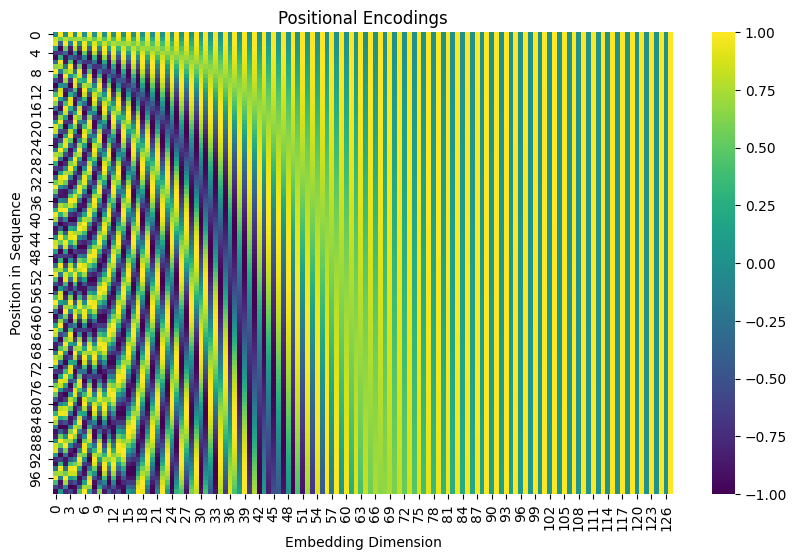

In [17]:
# Generate positional encodings
pos_encodings = positional_encoding(100, 128)

# Visualize the encodings as a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(pos_encodings[0], cmap='viridis')
plt.xlabel('Embedding Dimension')
plt.ylabel('Position in Sequence')
plt.title('Positional Encodings')
plt.show()

In [18]:
d_model = 512
pe = positional_encoding(position=4, embedding_dim=d_model).numpy()[0]  # shape: (4, 512)

dims = [0, 1, 2, 509, 510, 511]
for pos in [0, 1, 2, 3]:
    vals = pe[pos, dims]
    print(f"pos={pos}: " + ", ".join([f"D{d}={v:.15f}" for d, v in zip(dims, vals)]))

pos=0: D0=0.000000000000000, D1=1.000000000000000, D2=0.000000000000000, D509=1.000000000000000, D510=0.000000000000000, D511=1.000000000000000
pos=1: D0=0.841470956802368, D1=0.540302276611328, D2=0.821856200695038, D509=1.000000000000000, D510=0.000103663289337, D511=1.000000000000000
pos=2: D0=0.909297406673431, D1=-0.416146844625473, D2=0.936414718627930, D509=1.000000000000000, D510=0.000207326578675, D511=1.000000000000000
pos=3: D0=0.141120001673698, D1=-0.989992499351501, D2=0.245085418224335, D509=0.999999940395355, D510=0.000310989882564, D511=0.999999940395355


**The position encoding in the lecture slide:**
![b301bce6-b4c1-44e9-891d-b39e45195b7a.png](attachment:6f1035cc-f5e2-4b5b-b2fd-d93939bc92a1.png)

## Masking   <a name="3-2"></a>

In [19]:
def create_padding_mask(seq):
    """
    Creates a padding mask for a given sequence.

    Args:
        seq (tensor): A tensor of shape (batch_size, seq_len) containing the sequence.

    Returns:
        A tensor of shape (batch_size, 1, 1, seq_len) containing a mask that is 1 where the sequence is padded, and 0 otherwise.
    """
    # Convert the sequence to a boolean tensor where True indicates a pad token (value 0).
    seq = tf.cast(tf.math.equal(seq, 0), tf.float32)

    # Add an extra dimension to the mask to add the padding to the attention logits.
    return seq[:, tf.newaxis, tf.newaxis, :]  # Added attention head dimension

The create_look_ahead_mask function generates a look-ahead mask (or causal mask) for a Transformer’s decoder. This mask prevents the model from "seeing" or **attending** to future tokens when predicting each token in the sequence.

Example (size = 5):
    
    tf.ones((5, 5))

[<br>
[1, 1, 1, 1, 1],<br>
 [1, 1, 1, 1, 1],<br>
 [1, 1, 1, 1, 1],<br>
 [1, 1, 1, 1, 1],<br>
 [1, 1, 1, 1, 1]<br>
 ]<br>

    tf.linalg.band_part(tf.ones((5, 5)), -1, 0)
 [<br>
 [1, 0, 0, 0, 0],<br>
 [1, 1, 0, 0, 0],<br>
 [1, 1, 1, 0, 0],<br>
 [1, 1, 1, 1, 0],<br>
 [1, 1, 1, 1, 1]<br>
 ]<br>

    mask = 1 - tf.linalg.band_part(tf.ones((5, 5)), -1, 0)

[<br>
[0, 1, 1, 1, 1],<br>
 [0, 0, 1, 1, 1],<br>
 [0, 0, 0, 1, 1],<br>
 [0, 0, 0, 0, 1],<br>
 [0, 0, 0, 0, 0]<br>
 ]<br>

In [20]:
def create_look_ahead_mask(size):
    """
    Creates a look-ahead mask used during training the decoder of a transformer.
    tf.linalg.band_part(input, num_lower, num_upper) extracts the band part of a matrix.

    num_lower: Number of sub-diagonals to keep. -1 indicates keeping all sub-diagonals below the main diagonal.
    num_upper: Number of super-diagonals to keep. 0 means only the main diagonal is kept above.

    Args:
        size (int): The size of the mask.

    Returns:
        tf.Tensor: A lower triangular matrix of shape (size, size) with ones on the diagonal
            and zeros below the diagonal.
    """
    # create a matrix with ones on the diagonal and zeros below the diagonal
    mask = 1 - tf.linalg.band_part(tf.ones((size, size)), -1, 0)

    return mask

In [21]:
def create_masks(inputs, targets):
    """
    Creates masks for the input sequence and target sequence.

    Args:
        inputs: Input sequence tensor.
        targets: Target sequence tensor.

    Returns:
        A tuple of three masks: the encoder padding mask, the combined mask used in the first attention block,
        and the decoder padding mask used in the second attention block.
    """

    # Create the encoder padding mask.
    enc_padding_mask = create_padding_mask(inputs)

    # Create the decoder padding mask.
    # Used in the decoder’s cross-attention (decoder attending to encoder outputs).
    dec_padding_mask = create_padding_mask(inputs)

    # Create the look ahead mask for the first attention block.
    # It is used to pad and mask future tokens in the tokens received by the decoder.
    look_ahead_mask = create_look_ahead_mask(tf.shape(targets)[1])

    # Create the decoder target padding mask.
    dec_target_padding_mask = create_padding_mask(targets)

    # Combine the look ahead mask and decoder target padding mask for the first attention block.
    combined_mask = tf.maximum(dec_target_padding_mask, look_ahead_mask)
    #  The look_ahead_mask (shape (S_tgt, S_tgt)) is broadcasted to (B, 1, S_tgt, S_tgt) to match the shape of dec_target_padding_mask.
    # Output Shape of combined_mask: (B, 1, S_tgt, S_tgt)

    return enc_padding_mask, combined_mask, dec_padding_mask


# <span style="color: Navy"> Self Attention</span>
The self-attention mechanism is a core component of the Transformer model, allowing it to model dependencies between different positions in a sequence effectively. Self-attention is applied in both the encoder and decoder layers of a Transformer to help the model focus on relevant parts of the input sequence when encoding or generating output tokens.
![1751235745846.png](attachment:a53e4ce2-2989-4c61-82d8-12be46375f50.png)

In [22]:
def scaled_dot_product_attention(q, k, v, mask):
    """
    Computes the scaled dot product attention weight for the query (q), key (k), and value (v) vectors.
    The attention weight is a measure of how much focus should be given to each element in the sequence of values (v)
    based on the corresponding element in the sequence of queries (q) and keys (k).

    Args:
    q: query vectors; shape (batch, num_heads, seq_len, d_k)
    k: key vectors; shape  (batch, num_heads, seq_len, d_k)
    v: value vectors; shape  (batch, num_heads, seq_len, d_v)
    mask: (optional) mask to be applied to the attention weights

    Returns:
    output: The output of the scaled dot product attention computation; shape   (batch, num_heads, seq_len, d_v)
    attention_weights: The attention weights
    """
    # Compute dot product of query and key vectors
    matmul_qk = tf.matmul(q, k, transpose_b=True)

    # Compute the square root of the depth of the key vectors
    dk = tf.cast(tf.shape(k)[-1], dtype=tf.float32)
    scaled_dk = tf.math.sqrt(dk)

    # Compute scaled attention logits by dividing dot product by scaled dk
    scaled_attention_logits = matmul_qk / scaled_dk

    # Apply mask to the attention logits (if mask is not None)
    if mask is not None:
        scaled_attention_logits += (mask * -1e9)

    # Apply softmax to the scaled attention logits to get the attention weights
    attention_weights = tf.nn.softmax(scaled_attention_logits, axis=-1)

    # Compute the weighted sum of the value vectors using the attention weights >> (seq_len, seq_len) (seq_len, d_v)
    output = tf.matmul(attention_weights, v)

    return output, attention_weights


# <span style="color: Navy"> Multi-head Attention</span>

Multi-Head Attention is a key component of the Transformer model, allowing it to attend to information from multiple representation subspaces simultaneously. This mechanism is designed to improve the model's ability to capture different aspects of relationships between tokens in a sequence by using multiple "heads" or independent attention mechanisms.
![1751175296852.png](attachment:a2702678-b299-408b-a31a-5e48a1ebce0c.png)


In [23]:
class MultiHeadAttention(tf.keras.layers.Layer):

    def __init__(self, d_model, num_heads, dropout_rate=0.0):
        """
        Initializes the MultiHeadAttention layer.

        Args:
            d_model (int): The dimensionality of the model space.
            num_heads (int): The number of attention heads.
            dropout (float): The dropout rate to apply after the dense layer.
        """
        super(MultiHeadAttention, self).__init__()
        self.num_heads = num_heads
        self.d_model = d_model
        #  ensure  that the dimension of the embedding can be evenly split across attention heads
        assert d_model % num_heads == 0
        self.depth = self.d_model // self.num_heads

        # dense layers to project the input into queries, keys and values
        self.wq = Dense(d_model)
        self.wk = Dense(d_model)
        self.wv = Dense(d_model)

        # dropout layer
        self.dropout = Dropout(dropout_rate)

        # dense layer to project the output of the attention heads
        self.dense = Dense(d_model)

    def split_heads(self, x, batch_size):
        """
        Splits the last dimension of the tensor into (num_heads, depth).
        Transposes the result such that the shape is (batch_size, num_heads, seq_len, depth).

        Args:
            x (tensor): The tensor to be split.
            batch_size (int): The size of the batch.

        Returns:
            tensor: The tensor with the last dimension split into (num_heads, depth) and transposed.
        """
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(x, perm=[0, 2, 1, 3])

    def call(self, v, k, q, mask=None):
        """
        Applies the multi-head attention mechanism to the inputs.

        Args:
            v (tensor): The value tensor of shape (batch_size, seq_len, d_model).
            k (tensor): The key tensor of shape (batch_size, seq_len, d_model).
            q (tensor): The query tensor of shape (batch_size, seq_len, d_model).

            In self-attention, all seq_len values are the same.

            mask (tensor, optional): The mask tensor of shape (batch_size, seq_len_q, seq_len_k).
                                     Defaults to None.

        Returns:
            tensor: The output tensor of shape (batch_size, seq_len_q, d_model).
            tensor: The attention weights tensor of shape (batch_size, num_heads, seq_len_q, seq_len_k).
        """
        batch_size = tf.shape(q)[0]

        # Dense on the q, k, v vectors
        q = self.wq(q)
        k = self.wk(k)
        v = self.wv(v)

        # split the heads
        q = self.split_heads(q, batch_size)
        k = self.split_heads(k, batch_size)
        v = self.split_heads(v, batch_size)

        # split the queries, keys and values into multiple heads
        scaled_attention, attention_weights = scaled_dot_product_attention(q, k, v, mask)
        scaled_attention = tf.transpose(scaled_attention, perm=[0, 2, 1, 3])

        # reshape and add Dense layer
        concat_attention = tf.reshape(scaled_attention, (batch_size, -1, self.d_model))
        output = self.dense(concat_attention)
        output = self.dropout(output)

        return output, attention_weights


## Fully Connected NeuralNetwork <a name="4-3"></a>

In [24]:
def FeedForward(d_model, fully_connected_dim):
    """
    Creates a position-wise feedforward neural network used in Transformer blocks.

    Args:
        d_model (int): Dimensionality of the model (embedding/output size).
        fully_connected_dim (int): Hidden layer size in the FFN.

    Returns:
        tf.keras.Sequential: Two-layer feedforward network with ReLU activation.
    """
    return tf.keras.Sequential([
        tf.keras.layers.Dense(fully_connected_dim, activation='relu'),
        tf.keras.layers.Dense(d_model)
    ])

## Encoder
![855a007c-7a03-4980-811c-d84bb914ed00.png](attachment:f935397b-17e9-417a-b628-eb037b65c413.png)

In [25]:
class EncoderLayer(tf.keras.layers.Layer):
    def __init__(self, embedding_dim, num_heads, fully_connected_dim, dropout_rate=0.1):
        super(EncoderLayer, self).__init__()

        self.mha = MultiHeadAttention(embedding_dim, num_heads, dropout_rate)
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout = Dropout(dropout_rate)
        self.ffn = FeedForward(embedding_dim, fully_connected_dim)

    def call(self, x, training=False, mask=None):
        """
        Args:
            x: Input tensor of shape (batch_size, input_seq_len, embedding_dim)
            training: Boolean, whether in training mode (for dropout)
            mask: Attention mask to avoid attending to padding tokens

        Returns:
            Tensor of the same shape as input
        """

        # Multi-head self-attention
        attn_output, _ = self.mha(x, x, x, mask=mask)  # use keyword for mask
        out1 = self.layernorm1(attn_output + x)

        # Feedforward + dropout + norm
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout(ffn_output, training=training)  # ✅ use keyword for training
        out2 = self.layernorm2(ffn_output + out1)

        return out2

In [26]:
class Encoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, embedding_dim, num_heads, fully_connected_dim, input_vocab_size, maximum_position_encoding, dropout_rate=0.1):

        """
        Initializes the Encoder layer of the Transformer model.

        Args:
            num_layers (int): Number of stacked EncoderLayer layers in the encoder.
            embedding_dim (int): Dimensionality of the token embedding space.
            num_heads (int): Number of attention heads in each MultiHeadAttention layer.
            fully_connected_dim (int): Dimensionality of the fully connected feed-forward network in the EncoderLayer.
            input_vocab_size (int): Size of the input vocabulary for the embedding layer.
            maximum_position_encoding (int): Maximum allowed input sequence length for positional encoding.
            dropout_rate (float): Probability for dropout during training to prevent overfitting.
        """
        super(Encoder, self).__init__()

        self.num_layers = num_layers
        self.embedding_dim = embedding_dim

        # Embedding layer
        self.embedding = Embedding(input_vocab_size, embedding_dim)

        # Positional encoding
        self.pos_encoding = positional_encoding(maximum_position_encoding, embedding_dim)

        # Encoder layers
        self.enc_layers = [EncoderLayer(embedding_dim, num_heads, fully_connected_dim, dropout_rate) for _ in range(num_layers)]

        # Dropout layer
        self.dropout = Dropout(dropout_rate)

    def call(self, inputs, training=False, mask=None):
        """
        Forward pass for the Encoder layer.

        Args:
            inputs: Tensor of shape (batch_size, sequence_length), containing input token IDs.
            training: Boolean indicating whether the model is in training mode (activates dropout).
            mask: Tensor of shape (batch_size, sequence_length) used to mask out padding tokens in the input sequence.

        Returns:
            A tensor of shape (batch_size, sequence_length, embedding_dim), representing the encoded sequence.
        """

        # Get the sequence length
        seq_len = tf.shape(inputs)[1]

        # Embed the input sequence
        inputs = self.embedding(inputs)

        # Scale up the embeddings by sqrt(embedding_dim)
        inputs *= tf.math.sqrt(tf.cast(self.embedding_dim, tf.float32))

        # Add positional encodings to the input sequence
        inputs += self.pos_encoding[:, :seq_len, :]

        # Apply dropout to the input sequence
        inputs = self.dropout(inputs, training=training)

        # Pass the input sequence through the encoder layers
        for i in range(self.num_layers):
            inputs = self.enc_layers[i](inputs, training=training, mask=mask)

        # Return the encoded sequence
        return inputs

## Decoder

In [27]:
class DecoderLayer(tf.keras.layers.Layer):
    def __init__(self, embedding_dim, num_heads, fully_connected_dim, dropout_rate=0.1):
        """
        Initializes a single decoder layer of the transformer model.

        Args:
        embedding_dim: The dimension of the embedding space.
        num_heads: The number of attention heads to use.
        fully_connected_dim: The dimension of the feedforward network.
        rate: The dropout rate for regularization.
        """
        super(DecoderLayer, self).__init__()

        # Instantiate two instances of MultiHeadAttention.
        self.mha1 = MultiHeadAttention(embedding_dim, num_heads, dropout_rate)
        self.mha2 = MultiHeadAttention(embedding_dim, num_heads, dropout_rate)

        # Instantiate a fully connected feedforward network.
        self.ffn = FeedForward(embedding_dim, fully_connected_dim)

        # Instantiate three layer normalization layers with epsilon=1e-6.
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.layernorm3 = LayerNormalization(epsilon=1e-6)

        # Instantiate a dropout layer for regularization.
        self.dropout3 = Dropout(dropout_rate)

    def call(self, x, enc_output, training=False, look_ahead_mask=None, padding_mask=None):
        """
        Forward pass through the decoder layer.

        Args:
        x: The input to the decoder layer, a query vector.
        enc_output: The output from the top layer of the encoder, a set of attention vectors k and v.
        training: Whether to apply dropout regularization.
        look_ahead_mask: The mask to apply to the input sequence so that it can't look ahead to future positions.
        padding_mask: The mask to apply to the input sequence to ignore padding tokens.

        Returns:
        The output from the decoder layer, a tensor with the same shape as the input.
        The attention weights from the first multi-head attention layer.
        The attention weights from the second multi-head attention layer.
        """

        # Apply the first multi-head attention layer to the query vector x.
        # We pass x as all three inputs to the layer because this is a self-attention layer.
        # We pass look_ahead_mask as it is Causal Multi-Head Attention
        attn1, attn_weights_block1 = self.mha1(x, x, x, look_ahead_mask)

        # Add the original input to the output of the attention layer and apply layer normalization.
        out1 = self.layernorm1(attn1 + x)

        # Apply the second multi-head attention layer to the output from the first layer and the encoder output.
        # the call signature is: def call(self, v, k, q, mask=None):
        attn2, attn_weights_block2 = self.mha2(enc_output, enc_output, out1, padding_mask)

        # Add the output from the first layer to the output of the second layer and apply layer normalization.
        out2 = self.layernorm2(attn2 + out1)

        # Apply the feedforward network to the output of the second layer and apply dropout regularization.
        ffn_output = self.ffn(out2)
        ffn_output = self.dropout3(ffn_output, training=training)

        # Add the output from the second layer to the output of the feedforward network and apply layer normalization.
        out3 = self.layernorm3(ffn_output + out2)

        return out3, attn_weights_block1, attn_weights_block2


In [28]:
class Decoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, embedding_dim, num_heads, fully_connected_dim, target_vocab_size, maximum_position_encoding, dropout_rate=0.1):
        """
        Initializes the Decoder object.

        Args:
            num_layers (int): The number of Decoder layers.
            embedding_dim (int): The size of the embedding dimension.
            num_heads (int): The number of heads in the MultiHeadAttention layer.
            fully_connected_dim (int): The number of units in the feedforward network.
            target_vocab_size (int): The number of words in the target vocabulary.
            maximum_position_encoding (int): The maximum length of a sequence.
            dropout_rate (float): The rate at which to apply dropout.
        """
        super(Decoder, self).__init__()

        self.num_layers = num_layers
        self.embedding_dim = embedding_dim

        # create layers
        self.embedding = Embedding(target_vocab_size, embedding_dim)
        self.pos_encoding = positional_encoding(maximum_position_encoding, embedding_dim)
        self.dec_layers = [DecoderLayer(embedding_dim, num_heads, fully_connected_dim, dropout_rate=0.1) for _ in range(num_layers)]
        self.dropout = Dropout(dropout_rate)

    def call(self, x, enc_output, training, look_ahead_mask, padding_mask):
        """
        Executes the Decoder.

        Args:
            x (tf.Tensor): The input to the Decoder.
            enc_output (tf.Tensor): The output from the Encoder.
            training (bool): Whether the Decoder is in training mode.
            look_ahead_mask (tf.Tensor): The mask for self-attention in the MultiHeadAttention layer.
            padding_mask (tf.Tensor): The mask for padding in the MultiHeadAttention layer.

        Returns:
            tf.Tensor: The output from the Decoder.
            dict: A dictionary of attention weights.
        """
        seq_len = tf.shape(x)[1]
        attention_weights = {}

        # add embedding and positional encoding
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.embedding_dim, tf.float32))
        x += self.pos_encoding[:, :seq_len, :]
        x = self.dropout(x, training=training)

        # apply each layer of the decoder
        for i in range(self.num_layers):
            # pass through decoder layer i
            x, block1, block2 = self.dec_layers[i](
                x,
                enc_output,
                training=training,
                look_ahead_mask=look_ahead_mask,
                padding_mask=padding_mask
                )

            # record attention weights for block1 and block2
            attention_weights[f"decoder_layer{i + 1}_block1"] = block1
            attention_weights[f"decoder_layer{i + 1}_block2"] = block2

        return x, attention_weights

## Transformer

In [29]:
class Transformer(tf.keras.Model):
    """
    A Transformer model that takes in an input and target sequence and outputs a final prediction.

    Args:
        num_layers (int): Number of layers in the Encoder and Decoder.
        embedding_dim (int): Dimensionality of the embedding layer.
        num_heads (int): Number of attention heads used in the Transformer.
        fully_connected_dim (int): Dimensionality of the fully connected layer in the Encoder and Decoder.
        input_vocab_size (int): Size of the input vocabulary.
        target_vocab_size (int): Size of the target vocabulary.
        max_positional_encoding_input (int): Maximum length of the input sequence.
        max_positional_encoding_target (int): Maximum length of the target sequence.
        dropout_rate (float, optional): Dropout rate used in the Encoder and Decoder layers. Defaults to 0.1.
    """
    def __init__(self, num_layers, embedding_dim, num_heads, fully_connected_dim, input_vocab_size, target_vocab_size, max_positional_encoding_input, max_positional_encoding_target, dropout_rate=0.1):
        super(Transformer, self).__init__()

        # Initialize the Encoder and Decoder layers
        self.encoder = Encoder(num_layers, embedding_dim, num_heads, fully_connected_dim, input_vocab_size, max_positional_encoding_input, dropout_rate)
        self.decoder = Decoder(num_layers, embedding_dim, num_heads, fully_connected_dim, target_vocab_size, max_positional_encoding_target, dropout_rate)

        # Add a final dense layer to make the final prediction
        self.final_layer = tf.keras.layers.Dense(target_vocab_size, activation='softmax')

    def call(self, inp, tar, training, enc_padding_mask, look_ahead_mask, dec_padding_mask):
        """
        Perform a forward pass through the Transformer model.

        Args:
            inp (tf.Tensor): Input sequence tensor with shape (batch_size, input_seq_len).
            tar (tf.Tensor): Target sequence tensor with shape (batch_size, target_seq_len).
            training (bool): Whether the model is being trained or not.
            enc_padding_mask (tf.Tensor): Padding mask for the Encoder with shape (batch_size, 1, 1, input_seq_len).
            look_ahead_mask (tf.Tensor): Mask to prevent the Decoder from looking ahead in the target sequence with shape (batch_size, 1, target_seq_len, target_seq_len).
            dec_padding_mask (tf.Tensor): Padding mask for the Decoder with shape (batch_size, 1, 1, target_seq_len).

        Returns:
            tuple: A tuple containing the final output of the model and the attention weights of the Decoder.
        """
        # Pass the input sequence through the Encoder
        enc_output = self.encoder(inp, training=training, mask=enc_padding_mask)

        # Pass the target sequence and the output of the Encoder through the Decoder
        dec_output, attention_weights = self.decoder(
            tar,
            enc_output,
            training=training,
            look_ahead_mask=look_ahead_mask,
            padding_mask=dec_padding_mask
            )

        # Pass the output of the Decoder through the final dense layer to get the final prediction
        final_output = self.final_layer(dec_output)

        return final_output, attention_weights



# Training

## Initializing Hyperparameters <a name="5-1"></a>

In [30]:
# Set hyperparameters for the Transformer model
embedding_dim = 128  # dimensionality of the embeddings used for tokens in the input and target sequences
fully_connected_dim = 512  # dimensionality of the hidden layer of the feedforward neural network within the Transformer block
num_layers = 4  # number of Transformer blocks in the encoder and decoder stacks
num_heads = 4  # number of heads in the multi-head attention mechanism
dropout_rate = 0.1  # dropout rate for regularization

# Set vocabulary sizes for input and target sequences
input_vocab_size = len(tokenizer_fr.word_index) + 2  # add 2 for the start and end tokens
target_vocab_size = len(tokenizer_en.word_index) + 2  # add 2 for the start and end tokens

# Set maximum positional encoding values for input and target sequences
max_positional_encoding_input = 32  # maximum positional encoding value for input sequence
max_positional_encoding_target = 32  # maximum positional encoding value for target sequence

# Set the number of epochs and batch size for training
EPOCHS = 20
batch_size = 64

In [31]:
class CustomSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    """
    A custom learning rate schedule that uses a combination of
    a square root inverse decay and a warmup schedule.

    Args:
        embedding_dim (int): The dimension of the embedding.
        warmup_steps (int): The number of steps used for warmup.

    Returns:
        float: The learning rate value at a given step.
    """
    def __init__(self, embedding_dim, warmup_steps=4000):
        super(CustomSchedule, self).__init__()
        self.embedding_dim = tf.cast(embedding_dim, dtype=tf.float32)
        self.warmup_steps = tf.cast(warmup_steps, dtype=tf.float32)

    def __call__(self, step):
        """
        Compute the learning rate value for a given step using
        a combination of square root inverse decay and warmup.

        Args:
            step (int): The current step number.

        Returns:
            float: The learning rate value at the current step.
        """
        step = tf.cast(step, dtype=tf.float32)
        arg1 = tf.math.rsqrt(step)
        arg2 = step * (self.warmup_steps ** -1.5)
        return tf.math.rsqrt(self.embedding_dim) * tf.math.minimum(arg1, arg2)

# Create an instance of the custom learning rate schedule
learning_rate = CustomSchedule(embedding_dim)

## Loss Function and Metrics
**The loss function used to train the model is the SparseCategoricalCrossentropy.**

In [32]:
# Create an instance of the Transformer model
transformer = Transformer(num_layers, embedding_dim, num_heads,
                           fully_connected_dim, input_vocab_size, target_vocab_size,
                           max_positional_encoding_input, max_positional_encoding_target, dropout_rate)

# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate, beta_1=0.9, beta_2 = 0.98, epsilon = 1e-9)

# Define the loss object
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)


def loss_function(true_values, predictions):
    """
    Calculate the loss value for a given target sequence.

    Args:
        true_values (tf.Tensor): The true target sequence.
        predictions (tf.Tensor): The predicted target sequence.

    Returns:
        float: The loss value for the given target sequence.
    """
    # Create a mask to exclude the padding tokens
    mask = tf.math.logical_not(tf.math.equal(true_values, 0))

    # Compute the loss value using the loss object
    loss_ = loss_object(true_values, predictions)

    # Apply the mask to exclude the padding tokens
    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask

    # Calculate the mean loss value
    return tf.reduce_sum(loss_) / tf.reduce_sum(mask)

def accuracy_function(true_values, predictions):
    """
    Calculate the accuracy for a given target sequence.

    Args:
        true_values (tf.Tensor): The true target sequence.
        predictions (tf.Tensor): The predicted target sequence.

    Returns:
        float: The accuracy value for the given target sequence.
    """
    # Compute the accuracies using the true and predicted target sequences
    accuracies = tf.equal(true_values, tf.argmax(predictions, axis=2))

    # Create a mask to exclude the padding tokens
    mask = tf.math.logical_not(tf.math.equal(true_values, 0))

    # Apply the mask to exclude the padding tokens from the accuracies
    accuracies = tf.math.logical_and(mask, accuracies)
    accuracies = tf.cast(accuracies, dtype=tf.float32)
    mask = tf.cast(mask, dtype=tf.float32)

    # Calculate the mean accuracy value
    return tf.reduce_sum(accuracies) / tf.reduce_sum(mask)

# Define the training metrics
train_loss = tf.keras.metrics.Mean(name='train_loss')
train_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name='train_accuracy')

## Training Function

In [33]:
# the train function
train_step_signature = [
    tf.TensorSpec(shape=(batch_size, None), dtype=tf.int64),
    tf.TensorSpec(shape=(batch_size, None), dtype=tf.int64),
]

In [34]:
@tf.function(input_signature=train_step_signature)
def train_step(encoder_input, target):
    """
    Function to perform a single training step.

    Args:
    encoder_input (tf.Tensor): The input tensor for the encoder.
    target (tf.Tensor): The target tensor for the decoder.

    Returns:
    None.
    """

    # Slice the target tensor to get the input for the decoder
    decoder_input = target[:, :-1]

    # Slice the target tensor to get the expected output of the decoder
    expected_output = target[:, 1:]

    # Create masks for the encoder input, decoder input and the padding
    enc_padding_mask, combined_mask, dec_padding_mask = create_masks(encoder_input, decoder_input)

    # Perform a forward pass through the model
    with tf.GradientTape() as tape:
        predictions, _ = transformer(encoder_input,
                                     decoder_input,
                                     training=True,
                                     enc_padding_mask=enc_padding_mask,
                                     look_ahead_mask=combined_mask,
                                     dec_padding_mask=dec_padding_mask
                                    )

        # Calculate the loss between the predicted output and the expected output
        loss = loss_function(expected_output, predictions)

    # Calculate gradients and update the model parameters
    gradients = tape.gradient(loss, transformer.trainable_variables)
    optimizer.apply_gradients(zip(gradients, transformer.trainable_variables))

    # Update the training loss and accuracy metrics
    train_loss(loss)
    train_accuracy(expected_output, predictions)

## Training Loop

In [ ]:
# Record the start time
start_time = time.time()

for epoch in range(1, EPOCHS+1):
    # Reset the metrics at the start of the next epoch
    train_loss.reset_state()
    train_accuracy.reset_state()
    current_batch_index = 0

    # iterate through the dataset in batches of batch_size
    for i in range(int(len(english_sentences)/batch_size)):
        # get the input and target batch
        target_batch = tf.convert_to_tensor(np.array(english_sentences[current_batch_index:current_batch_index+batch_size]),dtype=tf.int64)
        input_batch = tf.convert_to_tensor(np.array(french_sentences[current_batch_index:current_batch_index+batch_size]),dtype=tf.int64)

        current_batch_index = current_batch_index + batch_size
        # call the train_step function to train the model using the current batch
        train_step(input_batch, target_batch)

    # print the epoch loss and accuracy after iterating through the dataset
    print (f'Epoch {epoch} Loss {train_loss.result():.4f} Accuracy {train_accuracy.result():.4f}')

# Record the end time
end_time = time.time()

# Calculate and print the duration
duration = end_time - start_time
print(f"The training ran for {duration} seconds.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'multi_head_attention' (of type MultiHeadAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'multi_head_attention_1' (of type MultiHeadAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  

Epoch 1 Loss 4.1874 Accuracy 0.3162
Epoch 2 Loss 1.8863 Accuracy 0.7603
Epoch 3 Loss 1.5391 Accuracy 0.7608
Epoch 4 Loss 1.1020 Accuracy 0.8017
Epoch 5 Loss 0.9409 Accuracy 0.8300
Epoch 6 Loss 0.7954 Accuracy 0.8470
Epoch 7 Loss 0.6420 Accuracy 0.8691
Epoch 8 Loss 0.5233 Accuracy 0.8896
Epoch 9 Loss 0.4358 Accuracy 0.9053
Epoch 10 Loss 0.3637 Accuracy 0.9208


# Evaluation

## Translation

In [ ]:
maxlen=30

def translate_helper(sentence):
    """
    Generate a translated sentence using the trained Transformer model.

    Args:
        sentence (str): Input sentence in French.

    Returns:
        Tensor of token IDs representing the translated English sentence.
    """

    # Add start/end markers to the sentence
    sentence = 'sos ' + sentence.strip() + ' eos'

    # Tokenize and pad the encoder input
    input_seq = tokenizer_fr.texts_to_sequences([sentence])
    input_seq = pad_sequences(input_seq, maxlen=maxlen, padding='post', truncating='post')
    encoder_input = tf.convert_to_tensor(input_seq, dtype=tf.int64)

    # Decoder starts with just 'sos'
    start_token = tokenizer_en.texts_to_sequences(['sos'])[0][0]
    decoder_input = tf.convert_to_tensor([[start_token]], dtype=tf.int64)

    for i in range(maxlen):
        # Create masks
        enc_padding_mask, combined_mask, dec_padding_mask = create_masks(encoder_input, decoder_input)

        # Run through transformer
        predictions, _ = transformer(
            encoder_input,
            decoder_input,
            training=False,
            enc_padding_mask=enc_padding_mask,
            look_ahead_mask=combined_mask,
            dec_padding_mask=dec_padding_mask
        )

        # Get the ID of the next token (last time step)
        predicted_id = tf.argmax(predictions[:, -1:, :], axis=-1)

        # If 'eos' token is predicted, stop
        eos_id = tokenizer_en.word_index.get('eos', -1)  # Use -1 as a fallback
        if tf.reduce_any(tf.equal(predicted_id, eos_id)):
            break

        # Append predicted token to decoder input
        decoder_input = tf.concat([decoder_input, predicted_id], axis=-1)

    return tf.squeeze(decoder_input, axis=0)  # Shape: (decoded_seq_len,)

## Translate Function <a name="6-2"></a>

In [ ]:
def translate(sentence):
    print(f'Input sentence: {sentence}\n')

    result = translate_helper(sentence).numpy().tolist()

    # Handle eos variants like 'eos.' or 'eos'
    eos_id = None
    for key in tokenizer_en.word_index:
        if key.startswith('eos'):
            eos_id = tokenizer_en.word_index[key]
            break

    sos_id = tokenizer_en.word_index.get('sos')

    # Truncate at eos if possible
    if eos_id is not None and eos_id in result:
        result = result[:result.index(eos_id)]

    # Remove sos if still present
    predicted_ids = [i for i in result if i != sos_id]

    predicted_sentence = tokenizer_en.sequences_to_texts([predicted_ids])[0]
    print(f'Translation: {predicted_sentence}')
    return predicted_sentence



In [ ]:
sentence = "california est généralement calme en mars"
translate(sentence)